# giFBA vs. dFBA: Flux Comparison (AH_BI)

Reaction-level comparison of giFBA and dFBA fluxes for the two-organism *A. hallii* (AH) / *B. infantis* (BI) community. Reads the preprocessed `data/AH_BI/fluxes_AH_BI.pkl`, `hyperparams_AH_BI.csv` and `model_names_AH_BI.csv` written by `process_results.py`.

Every run uses the same relative abundance (`[0.5, 0.5]`), so giFBA returns the same fluxes for every Monte Carlo sample and only the dFBA side changes. The flux frames hold only reactions active in at least one run, with rows and columns sorted identically for both methods. Hyperparameter-level analysis lives in `4_2_compare_hyperparameters.ipynb`, and the variable-N experiment in `4_4_compare_N_orgs_fluxes.ipynb`.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

import benchmark_analysis_utils as bau


## 1. Experiment config

In [2]:
config = bau.PRESETS["AH_BI"]
DATA_DIR = Path("data") / config.name
FIG_DIR = Path("../../figures/real_model_figs/dfba_benchmark")
FIG_DIR.mkdir(parents=True, exist_ok=True)

missing = [
    p for p in (
        DATA_DIR / f"hyperparams_{config.name}.csv",
        DATA_DIR / f"model_names_{config.name}.csv",
        DATA_DIR / f"fluxes_{config.name}.pkl",
    )
    if not p.exists()
]
if missing:
    raise FileNotFoundError(
        f"Missing processed files {[str(p) for p in missing]}; "
        f"run `python process_results.py --config {config.name}` first."
    )
config

ExperimentConfig(name='AH_BI', results_dir='Benchmark_AH_BI', max_time_s=86400, binning={'vmax': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'km': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.1f}', zero_floor=False), 'early_stop_window': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.0f}', zero_floor=False), 'early_stop_tol': BinSpec(spread='log', bins=3, min=None, max=None, fmt_bins='{:.1e}', zero_floor=False), 'rel_abund': BinSpec(spread='linear', bins=3, min=None, max=None, fmt_bins='{:.2f}', zero_floor=False), 'y0_factor': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True), 'y0_offset': BinSpec(spread='log', bins=2, min=None, max=None, fmt_bins='{:.2f}', zero_floor=True)})

## 2. Load processed results

In [3]:
df = pd.read_csv(DATA_DIR / f"hyperparams_{config.name}.csv", index_col=0)
for col in bau.present(["rel_abund_list", "media"], df):
    df[col] = df[col].map(json.loads)

model_names = pd.read_csv(DATA_DIR / f"model_names_{config.name}.csv", index_col=0).iloc[:, 0].map(json.loads)

# Per-run equivalence metrics written by process_results.py (see
# bau.calc_equivalence_metrics for the raw sums).
EQ_COLS = [
    "Abs_Diff_Sum", "Sum_Rel_Error", "N_nonzero_rxns", "N_rxns", "Sum_Abs_Flux",
    "gifba_abs_flux_sum", "dfba_abs_flux_sum",
    "MAE", "RPE",
]
eq_df = df[EQ_COLS].copy()

print(f"Loaded {len(df)} runs from {DATA_DIR}")
df.head()

Loaded 499 runs from data/AH_BI


,N_models,rel_abund_org_0,y0_factor,y0_offset,media,sum_N_rxns,sum_N_mets,vmax,km,solver_method,...,Abs_Diff_Sum,Sum_Rel_Error,N_nonzero_rxns,N_rxns,Sum_Abs_Flux,gifba_abs_flux_sum,dfba_abs_flux_sum,MAE,RPE,RPE_abs
run_id,,,,,,,,,,,,,,,,,,,,,
6177055_1,2,0.5,0.070548,0.010476,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,8.902151,0.117681,BDF,...,120.992317,-7.459148,520,2083,859.864976,485.842258,374.022717,0.058086,-0.003581,0.003581
6177055_10,2,0.5,0.010000,2.205131,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,5.094138,0.187382,BDF,...,276.986719,-12.849500,527,2083,699.962130,485.842258,214.119872,0.132975,-0.006169,0.006169
6177055_100,2,0.5,0.012328,0.018738,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,14.174742,0.148497,RK45,...,39.661503,-8.000000,294,2083,940.316783,485.842258,454.474524,0.019041,-0.003841,0.003841
6177055_101,2,0.5,0.008697,0.000100,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,5.857021,0.215443,BDF,...,245.733382,-8.517350,520,2083,731.996732,485.842258,246.154473,0.117971,-0.004089,0.004089
6177055_102,2,0.5,0.132194,0.000811,"{'EX_o2(e)': 0, 'EX_h2o(e)': -1000, 'EX_pi(e)'...",2083,1912,1.000000,0.599484,BDF,...,444.969014,-14.010291,518,2083,527.759220,485.842258,41.916961,0.213619,-0.006726,0.006726


In [4]:
fluxes = pd.read_pickle(DATA_DIR / f"fluxes_{config.name}.pkl")
gifba_fluxes_df = fluxes["gifba"]
dfba_fluxes_df = fluxes["dfba"]
flux_hist_counts = fluxes["flux_hist_counts"]
flux_hist_bin_edges = fluxes["flux_hist_bin_edges"]

assert gifba_fluxes_df.index.equals(df.index) and dfba_fluxes_df.index.equals(df.index)
assert gifba_fluxes_df.columns.equals(dfba_fluxes_df.columns)

print(f"giFBA fluxes: {gifba_fluxes_df.shape}")
print(f" dFBA fluxes: {dfba_fluxes_df.shape}")
print("giFBA: \n", gifba_fluxes_df.iloc[:5, :5])
print("dFBA: \n", dfba_fluxes_df.iloc[:5, :5])

giFBA fluxes: (499, 828)
 dFBA fluxes: (499, 828)
giFBA: 
              12PPDt___0  26DAPLLAT___0  4ABZt2___1  4HTHDR___0  4HTHDR___1
6177055_1           0.0      -0.009158         0.0    0.009158         0.0
6177055_10          0.0      -0.009158         0.0    0.009158         0.0
6177055_100         0.0      -0.009158         0.0    0.009158         0.0
6177055_101         0.0      -0.009158         0.0    0.009158         0.0
6177055_102         0.0      -0.009158         0.0    0.009158         0.0
dFBA: 
              12PPDt___0  26DAPLLAT___0  4ABZt2___1  4HTHDR___0  4HTHDR___1
6177055_1           0.0      -0.006975         0.0    0.006975         0.0
6177055_10          0.0      -0.003993         0.0    0.003993         0.0
6177055_100         0.0      -0.008527         0.0    0.008527         0.0
6177055_101         0.0       -0.00459         0.0     0.00459         0.0
6177055_102         0.0      -0.000781         0.0    0.000781         0.0


## 3. Flux magnitude histogram

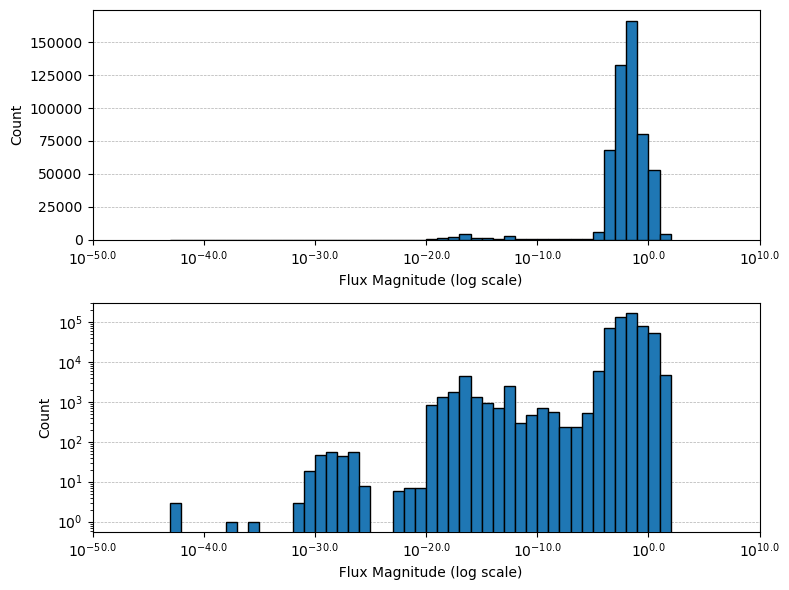

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(8, 6))
for ax, is_counts_log_scale in zip(axs, [False, True]):
    ax.bar(flux_hist_bin_edges[:-1], flux_hist_counts, width=1, align="edge", edgecolor="black", zorder=3)
    ax.set_xlabel("  Flux Magnitude (log scale)")
    if is_counts_log_scale:
        ax.set_yscale("log")
    ax.set_ylabel("Count")
    x_ticks = ax.get_xticks()
    ax.set_xticks(x_ticks)
    ax.set_xticklabels([r"$10^{{{}}}$".format(float(x)) for x in x_ticks])
    ax.grid(axis="y", linestyle="--", linewidth=0.5, zorder=0)

plt.tight_layout()
plt.savefig(FIG_DIR / f"flux_magnitude_histogram_{config.name}.svg", dpi=300, bbox_inches="tight")
plt.show()

## 4. Filter out zero-growth runs

The zero-growth runs are the ones that hit the cluster time limit, which `process_results.py` records with all-zero fluxes. Every remaining run should share one giFBA solution.

In [6]:
times = df["dfba_termination_t"]
print(sum(times == 100), "out of", len(times), "simulations terminated without convergence")

zero_growth_mask = eq_df["Sum_Abs_Flux"] == 0
print(sum(zero_growth_mask), "out of", len(zero_growth_mask), "simulations have 0 growth")

filter_mask = ~zero_growth_mask
df_filtered = df[filter_mask]
eq_df_filtered = eq_df[filter_mask]

gifba_kept = gifba_fluxes_df[filter_mask].astype("float64")
max_spread = (gifba_kept.max() - gifba_kept.min()).max()
print(f"Largest spread of any giFBA flux across the {len(gifba_kept)} kept runs: {max_spread:.3g}")
assert np.allclose(gifba_kept, gifba_kept.iloc[0], rtol=1e-9, atol=1e-9), "giFBA fluxes differ between runs"

469 out of 499 simulations terminated without convergence
4 out of 499 simulations have 0 growth
Largest spread of any giFBA flux across the 495 kept runs: 0


## 5. dFBA cost vs. error, and best/worst flux comparison

Left: dFBA pFBA call count against MAE for each run. giFBA makes the same number of pFBA calls in every run, so it is drawn as a single dashed line.

Middle/right: giFBA vs. dFBA flux per reaction for the lowest- and highest-MAE runs, colored by organism. Hover over a point for the reaction, organism and both fluxes.

In [ ]:
ORG_SHORT = {
    "Eubacterium_hallii_DSM_3353": "AH",
    "Bifidobacterium_longum_infantis_ATCC_15697": "BI",
}


def org_labels(run_id: str, columns: pd.Index) -> pd.Series:
    """Maps each flux column of one run to "AH" or "BI"."""
    names = model_names.get(run_id)
    return pd.Series(
        [ORG_SHORT[bau.get_org_label(names, bau.get_org_index(c))] for c in columns],
        index=columns,
    )


best_idx = eq_df_filtered["MAE"].idxmin()
worst_idx = eq_df_filtered["MAE"].idxmax()
assert df_filtered["gifba_pfba_calls"].nunique() == 1, "giFBA pFBA call count differs between runs"
gifba_calls = int(df_filtered["gifba_pfba_calls"].iloc[0])

fig = make_subplots(
    rows=1, cols=3,
    column_widths=[0.38, 0.31, 0.31],
    horizontal_spacing=0.07,
    subplot_titles=(
        "dFBA cost vs. error",
        f"Best MAE (MAE = {df.loc[best_idx, 'MAE']:.2e}, {df.loc[best_idx, 'solver_method']})",
        f"Worst MAE (MAE = {df.loc[worst_idx, 'MAE']:.2e}, {df.loc[worst_idx, 'solver_method']})",
    ),
)

for solver, color in bau.SOLVER_COLORS.items():
    runs = df_filtered[df_filtered["solver_method"] == solver]
    fig.add_trace(
        go.Scatter(
            x=runs["MAE"], y=runs["dfba_pfba_calls"], mode="markers", name=solver,
            marker=dict(size=6, color=color, opacity=0.7),
            customdata=runs.index,
            hovertemplate="run %{customdata}<br>MAE: %{x:.3g}<br>dFBA pFBA calls: %{y:,d}<extra>" + solver + "</extra>",
            legend="legend",
        ),
        row=1, col=1,
    )
fig.add_hline(y=gifba_calls, line_dash="dash", line_color="black", line_width=1.2, row=1, col=1)
# Dummy trace so the giFBA line appears in the legend.
fig.add_trace(go.Scatter(x=[None], y=[None], mode="lines", line=dict(color="black", dash="dash"),
                         name=f"giFBA ({gifba_calls} pFBA calls)", legend="legend"), row=1, col=1)

for run_id, tag in ((best_idx, "best"), (worst_idx, "worst")):
    fig.add_annotation(x=np.log10(df_filtered.loc[run_id, "MAE"]), y=np.log10(df_filtered.loc[run_id, "dfba_pfba_calls"]),
                       text=tag, showarrow=True, arrowhead=0, ax=0, ay=-25, row=1, col=1)
fig.update_xaxes(type="log", title_text="MAE (giFBA vs. dFBA)", showgrid=True, row=1, col=1)
# Floor at 1 call so the giFBA line clears the bottom edge; log-axis ranges are in log10 units.
y_top = np.log10(df_filtered["dfba_pfba_calls"].max()) + 0.1
fig.update_yaxes(type="log", title_text="pFBA calls", range=(1, y_top), showgrid=True, row=1, col=1)

for col, run_id in ((2, best_idx), (3, worst_idx)):
    gifba_s = gifba_fluxes_df.loc[run_id].astype("float64")
    dfba_s = dfba_fluxes_df.loc[run_id].reindex(gifba_s.index).astype("float64")
    orgs = org_labels(run_id, gifba_s.index)
    for org, color in bau.AH_BI_ORG_COLORS.items():
        mask = (orgs == org).to_numpy()
        fig.add_trace(
            go.Scatter(
                x=gifba_s[mask], y=dfba_s[mask], mode="markers", name=org,
                marker=dict(size=6, color=color, opacity=0.75),
                customdata=[rxn.rsplit("___", 1)[0] for rxn in gifba_s.index[mask]],
                hovertemplate="%{customdata} (" + org + ")<br>giFBA: %{x:.4g}<br>dFBA: %{y:.4g}<extra></extra>",
                legend="legend2", showlegend=col == 2,
            ),
            row=1, col=col,
        )
    lo = min(gifba_s.min(), dfba_s.min())
    hi = max(gifba_s.max(), dfba_s.max())
    pad = 0.05 * (hi - lo)
    lo, hi = lo - pad, hi + pad
    fig.add_trace(
        go.Scatter(x=[lo, hi], y=[lo, hi], mode="lines", line=dict(color="black", dash="dash", width=1),
                   opacity=0.6, name="y = x", hoverinfo="skip", legend="legend2", showlegend=col == 2),
        row=1, col=col,
    )
    fig.add_hline(y=0, line_color="black", line_width=0.8, opacity=0.2, row=1, col=col)
    fig.add_vline(x=0, line_color="black", line_width=0.8, opacity=0.2, row=1, col=col)
    fig.update_xaxes(title_text="giFBA flux", range=(lo, hi), showgrid=True, row=1, col=col)
    fig.update_yaxes(title_text="dFBA flux", range=(lo, hi), showgrid=True, row=1, col=col)

fig.update_layout(
    template="simple_white",
    height=550, width=1500,
    xaxis=dict(exponentformat="power",  showexponent="all"),
    yaxis=dict(exponentformat="power",  showexponent="all"),
    legend=dict(title=dict(text="dFBA solver"), orientation="h", x=0.18, y=-0.18, xanchor="center", yanchor="top"),
    legend2=dict(title=dict(text="Organism"), orientation="h", x=0.68, y=-0.18, xanchor="center", yanchor="top"),
)
fig.show()
fig.write_html(FIG_DIR / f"dfba_calls_vs_mae_flux_comparison_{config.name}.html")


### Why the MAE range has a hard floor and ceiling

**Floor (MAE ≈ 3.40e-3): alternate optima, not numerical error.** About 80 runs land on exactly MAE = 0.003402, and in those runs dFBA's total absolute flux matches giFBA's to within 1e-5 (485.842). The entire difference is in AH's interchangeable reaction pairs, where pFBA is degenerate and the LP solver picks a route arbitrarily:

| Reaction pair | giFBA | dFBA |
|---|---|---|
| `HSDy` / `HSDx` (NADPH vs. NADH homoserine dehydrogenase) | 1.767 / −1.933 | 0 / −0.167 |
| `DMPPS` / `DMPPS2r` | 0.009 / 0 | 1.776 / −1.767 |
| `GTPCII`, `DHPPDA` / `GTPCII2`, `DHPPDA2` | second route | first route |

4 × 1.76658 + 4 × 0.004918 = 7.086, and 7.086 / 2083 reactions = 0.003402. The two runs below the floor (`6177055_86`, `6177055_199`, both RK45) are the ones where dFBA happened to choose giFBA's routes for AH, leaving only a smaller `DMPPS`/`IPDPS` swap in BI (~0.006).

**Ceiling (MAE ≈ 0.214): the lower bound of the sampled `vmax`.** log MAE and log `vmax` correlate at r = −0.93. dFBA uptake is capped by Michaelis–Menten kinetics, so its fluxes shrink with `vmax`, while giFBA always reaches Σ|flux| = 485.8. At the smallest sampled value (`vmax` = 1, 8 runs) dFBA reaches only Σ|flux| ≈ 42, which gives MAE ≈ (485.8 − 42) / 2083 ≈ 0.213 whatever the other hyperparameters are. The largest differences there are fermentation exchanges (CO₂, H₂, lactate). This ceiling comes from the sampling range and would move if `vmax` were sampled lower.

| `vmax` | median MAE | median dFBA Σ\|flux\| |
|---|---|---|
| 1 | 0.214 | 41.9 |
| 1–2 | 0.203 | 63.8 |
| 5–10 | 0.107 | 270 |
| 20–50 | 0.0035 | 485.8 |

MAE is normalised by all 2083 reactions, including those inactive in both methods, so absolute values are roughly 4–5× smaller than a per-active-reaction average.

## 6. Hyperparameters of the best/worst runs

In [8]:
param_cols = bau.present(
    ["vmax", "km", "rel_abund", "y0_factor", "y0_offset", "solver_method",
     "early_stop_window", "early_stop_tol", "gifba_iter_converged",
     "gifba_periodicity", "dfba_pfba_calls", "gifba_pfba_calls", "dfba_solve_time", "gifba_solve_time",
     "log10_time_ratio", "log10_pfba_call_ratio", "MAE", "RPE"],
    df,
)
print(pd.DataFrame({
    "Best Run": df.loc[best_idx, param_cols],
    "Worst Run": df.loc[worst_idx, param_cols],
}).to_string() )

                         Best Run Worst Run
vmax                    34.304693       1.0
km                       0.376494  0.954548
y0_factor                0.002477  0.265609
y0_offset                  0.0001  0.774264
solver_method                RK45      RK45
early_stop_window              10        26
early_stop_tol           0.000004       0.0
gifba_iter_converged            7         7
gifba_periodicity               2         2
dfba_pfba_calls             19492       208
gifba_pfba_calls               32        32
dfba_solve_time        871.746843  7.155121
gifba_solve_time         8.652187  8.058501
log10_time_ratio         2.003265 -0.051637
log10_pfba_call_ratio    2.784706  0.812913
MAE                      0.000036  0.213662
RPE                      0.000963 -0.002506


## 7. Per-reaction absolute difference for a single run

In [9]:
RUN_ID = best_idx

abs_diff = (gifba_fluxes_df.loc[RUN_ID] - dfba_fluxes_df.loc[RUN_ID]).abs()
factor = (gifba_fluxes_df.loc[RUN_ID] / dfba_fluxes_df.loc[RUN_ID]).astype("float64")
run_comparison = pd.DataFrame({
    "gifba": gifba_fluxes_df.loc[RUN_ID],
    "dfba": dfba_fluxes_df.loc[RUN_ID],
    "abs_diff": abs_diff,
    "factor": factor
})
run_comparison["organism"] = org_labels(RUN_ID, run_comparison.index)

print(f"Run {RUN_ID}: MAE = {df.loc[RUN_ID, 'MAE']:.3e}")
run_comparison.sort_values("abs_diff", ascending=False).head(20)

Run 6177055_86: MAE = 3.591e-05


,gifba,dfba,abs_diff,factor,organism
IPDPS___1,0.039151,0.032976,0.006175,1.187260,AH
DMPPS2r___1,0.006174,0.0,0.006174,inf,AH
DMPPS___1,0.0,0.006174,0.006174,0.000000,AH
IPDPS2___1,0.022593,0.028763,0.00617,0.785491,AH
DHPPDA2___0,0.004918,0.0,0.004918,inf,BI
GTPCII2___0,0.004918,0.0,0.004918,inf,BI
GTPCII___0,0.0,0.004917,0.004917,0.000000,BI
DHPPDA___0,0.0,0.004917,0.004917,0.000000,BI
H2td___0,15.870296,15.869162,0.001134,1.000071,BI
EX_h2(e)___0,15.870296,15.869162,0.001134,1.000071,BI
